# Exploration du jeu d’entraînement

L’objectif de ce notebook est de comprendre les traces d’utilisation de Copilote et d’identifier les habitudes ou caractéristiques susceptibles de distinguer les utilisateurs.

Chaque ligne correspond à une session. La variable cible est `util`, l’identifiant de l’utilisateur.

Cette exploration porte uniquement sur `train.csv`. Le fichier original est lu sans être modifié. Les données brutes sont conservées dans `df_raw` et les transformations sont réalisées sur une copie de travail, `df_train`.

In [1]:
# Importer les bibliothèques et les outils.
from pathlib import Path
import re

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Construire le chemin du fichier d’entraînement.
DATA_PATH = (
    Path(r"C:\Users\Rog strix Scar\Desktop\BE_MachineLearning")
    / "data"
    / "train.csv"
)

print("Fichier trouvé :", DATA_PATH.is_file())

Fichier trouvé : True


## Chargement des sessions

Le fichier contient un nombre variable de traces par session. Nous lisons les lignes une à une et conservons leurs traces dans des listes, puis créons un DataFrame avec une ligne par session.

- `session_id` : numéro de la ligne d’origine, utilisé comme repère.
- `util` : identité de l’utilisateur, qui sera la cible à prédire.
- `navigateur` : navigateur utilisé pendant la session.
- `traces` : liste des actions et des marqueurs temporels.

In [2]:
sessions = []

with DATA_PATH.open(encoding="utf-8-sig") as fichier:
    for numero_ligne, ligne in enumerate(fichier, start=1):
        champs = ligne.rstrip("\r\n").split(",")

        if len(champs) < 3:
            raise ValueError(
                f"Ligne {numero_ligne} : format inattendu : {ligne}"
            )

        sessions.append({
            "session_id": numero_ligne,
            "util": champs[0],
            "navigateur": champs[1],
            "traces": champs[2:],
        })

# Créer le tableau des données brutes.
df_raw = pd.DataFrame(sessions)

print("Nombre de sessions :", len(df_raw))
df_raw.head(20)

Nombre de sessions : 3279


,session_id,util,navigateur,traces
0,1,nuh,Firefox,[Création d'un écran(infologic.core.accueil.Ac...
1,2,muz,Google Chrome,[Création d'un écran(infologic.core.gui.contro...
2,3,zrx,Microsoft Edge,[Affichage d'une dialogue(infologic.core.gui.c...
3,4,pou,Firefox,[Création d'un écran(infologic.core.gui.contro...
4,5,ald,Google Chrome,[Affichage d'une dialogue(infologic.acti.modul...
5,6,shh,Firefox,[Création d'un écran(infologic.crm.modules.CRM...
6,7,fwf,Firefox,"[Exécution d'un bouton, t5, Exécution d'un bou..."
7,8,slq,Google Chrome,"[Exécution d'un bouton, Exécution d'un bouton,..."
8,9,cje,Google Chrome,[Création d'un écran(infologic.core.accueil.Ac...
9,10,byo,Firefox,[Création d'un écran(infologic.core.accueil.Ac...


## Création d’une copie de travail

`df_raw` conserve les données brutes chargées en mémoire. Nous créons `df_train` pour travailler indépendamment de ce tableau de référence.

`copy(deep=True)` copie le DataFrame, mais ne copie pas récursivement les listes contenues dans ses cellules. Nous copions donc aussi chaque liste de la colonne `traces` avec `apply(list)`.

Cette opération crée une copie en mémoire ; elle n’écrit aucun fichier sur le disque.

In [3]:
# Copier le tableau et les listes de traces.
df_train = df_raw.copy(deep=True)
df_train["traces"] = df_raw["traces"].apply(list)

print("Nombre de sessions dans la copie :", len(df_train))
print("Contenu identique au départ :", df_train.equals(df_raw))

df_train.head(20)

Nombre de sessions dans la copie : 3279
Contenu identique au départ : True


,session_id,util,navigateur,traces
0,1,nuh,Firefox,[Création d'un écran(infologic.core.accueil.Ac...
1,2,muz,Google Chrome,[Création d'un écran(infologic.core.gui.contro...
2,3,zrx,Microsoft Edge,[Affichage d'une dialogue(infologic.core.gui.c...
3,4,pou,Firefox,[Création d'un écran(infologic.core.gui.contro...
4,5,ald,Google Chrome,[Affichage d'une dialogue(infologic.acti.modul...
5,6,shh,Firefox,[Création d'un écran(infologic.crm.modules.CRM...
6,7,fwf,Firefox,"[Exécution d'un bouton, t5, Exécution d'un bou..."
7,8,slq,Google Chrome,"[Exécution d'un bouton, Exécution d'un bouton,..."
8,9,cje,Google Chrome,[Création d'un écran(infologic.core.accueil.Ac...
9,10,byo,Firefox,[Création d'un écran(infologic.core.accueil.Ac...


## Observation d’une session

Nous examinons la première session pour distinguer les actions, comme `Double-clic`, des marqueurs temporels, comme `t5`.

Le nombre de traces comprend les actions **et** les marqueurs temporels : il ne représente pas uniquement le nombre d’actions. Les informations entre parenthèses, chevrons ou dollars précisent le contexte de certaines actions.

In [4]:
# Sélectionner la première session par sa position dans le tableau.
session = df_train.iloc[0]

print("Session :", session["session_id"])
print("Utilisateur :", session["util"])
print("Navigateur :", session["navigateur"])
print("Nombre de traces :", len(session["traces"]))
print("\nLes 20 premières traces :")

for trace in session["traces"][:20]:
    print(trace)

Session : 1
Utilisateur : nuh
Navigateur : Firefox
Nombre de traces : 3128

Les 20 premières traces :
Création d'un écran(infologic.core.accueil.AccueilController)
Affichage d'une dialogue
Exécution d'un bouton
Fermeture d'une dialogue
Affichage d'une dialogue
Exécution d'un bouton
Fermeture d'une dialogue
Création d'un écran(infologic.core.gui.controllers.nested.InputFormNestedWindow)
t5
Exécution d'un bouton(MAINT)
Affichage d'une dialogue
Fermeture d'une dialogue
Double-clic
Exécution d'un bouton
Lancement d'une stat(infologic.core.gui.controllers.nested.homeview.InputFormHomeView)
Affichage d'un toast
Lancement d'une stat(infologic.core.gui.controllers.nested.homeview.InputFormHomeView)
t10
Affichage d'une dialogue(MAINT)
Exécution d'un bouton


## Vérification des données

Nous examinons les valeurs manquantes dans les colonnes, les identifiants utilisateur et navigateurs vides, ainsi que les champs vides à l’intérieur des listes de traces. Une chaîne vide est différente d’une valeur manquante.

Aucune session n’est supprimée à cette étape.

In [5]:
# Examiner la structure du tableau et les valeurs manquantes.
df_train.info()

print("\nValeurs manquantes dans les colonnes :")
print(df_train.isna().sum())

# Vérifier aussi les chaînes vides ou composées uniquement d’espaces.
print("\nIdentifiants utilisateur vides :")
print(df_train["util"].str.strip().eq("").sum())

print("\nNavigateurs vides :")
print(df_train["navigateur"].str.strip().eq("").sum())

<class 'pandas.DataFrame'>
RangeIndex: 3279 entries, 0 to 3278
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   session_id  3279 non-null   int64 
 1   util        3279 non-null   str   
 2   navigateur  3279 non-null   str   
 3   traces      3279 non-null   object
dtypes: int64(1), object(1), str(2)
memory usage: 102.6+ KB

Valeurs manquantes dans les colonnes :
session_id    0
util          0
navigateur    0
traces        0
dtype: int64

Identifiants utilisateur vides :
0

Navigateurs vides :
0


In [6]:
# Vérifier les éléments à l’intérieur des listes de traces.
def compter_traces_vides(traces):
    compteur = 0
    for trace in traces:
        if trace.strip() == "":
            compteur += 1
    return compteur

nb_traces_vides = df_train["traces"].apply(compter_traces_vides).sum()
print("\nChamps de traces vides :", nb_traces_vides)


Champs de traces vides : 0


## Première interprétation

Le jeu d’entraînement contient **3 279 sessions**. Chaque session a été organisée en quatre informations : son numéro de ligne (`session_id`), l’identité de l’utilisateur (`util`), le navigateur utilisé et la liste des traces.

Une copie de travail a été créée pour conserver les données brutes comme référence. Les transformations suivantes seront réalisées sur `df_train`, tandis que `df_raw` sera conservé sans modification.

Les vérifications ne montrent aucune valeur manquante dans les quatre colonnes, aucun identifiant utilisateur vide, aucun navigateur vide et aucun champ de trace vide. La structure obtenue est donc exploitable pour poursuivre l’exploration. Cela ne garantit toutefois pas que toutes les sessions soient pertinentes ou exemptes d’anomalies : leur contenu reste à examiner.

La première session observée appartient à l’utilisateur `nuh`, utilisant Firefox. Elle contient **3 128 traces**, comprenant des actions et des marqueurs temporels tels que `t5` et `t10`. Ce nombre ne correspond donc pas uniquement au nombre d’actions. Les traces peuvent aussi fournir des informations sur les écrans ou le contexte de travail.

## Vérification des sessions dupliquées

Un utilisateur peut apparaître plusieurs fois, car il peut réaliser plusieurs sessions. Cette répétition est normale.

Nous recherchons les sessions ayant exactement le même utilisateur, le même navigateur et la même séquence de traces. Le numéro `session_id` est exclu de la comparaison, car il est unique pour chaque ligne.

In [7]:
verification = df_train[["util", "navigateur", "traces"]].copy()
verification["traces"] = verification["traces"].apply(tuple)

doublons = verification.duplicated(keep=False)

print(
    "Sessions appartenant à un groupe de doublons :",
    doublons.sum(),
)

print(
    "Occurrences supplémentaires identiques :",
    verification.duplicated().sum(),
)

display(df_train.loc[doublons])

Sessions appartenant à un groupe de doublons : 0
Occurrences supplémentaires identiques : 0


,session_id,util,navigateur,traces


### Interprétation des doublons

Aucune session strictement identique n’a été détectée dans le jeu d’entraînement. Les deux compteurs de doublons valent zéro.

Ce résultat n’exclut pas la présence de sessions très similaires.

## Exploration des sessions par navigateur

Nous calculons le nombre de sessions réalisées avec chaque navigateur et leur part dans le jeu d’entraînement. Les pourcentages portent sur les sessions, et non sur le nombre d’utilisateurs.

In [8]:
sessions_par_navigateur=df_train["navigateur"].value_counts()

resume_navigateurs = pd.DataFrame({
    "nb_sessions":sessions_par_navigateur,
    "pourcentage":(sessions_par_navigateur / len(df_train) * 100).round(2),
})

display(resume_navigateurs)

,nb_sessions,pourcentage
navigateur,,
Firefox,1466,44.71
Google Chrome,1339,40.84
Microsoft Edge,451,13.75
Opera,23,0.70


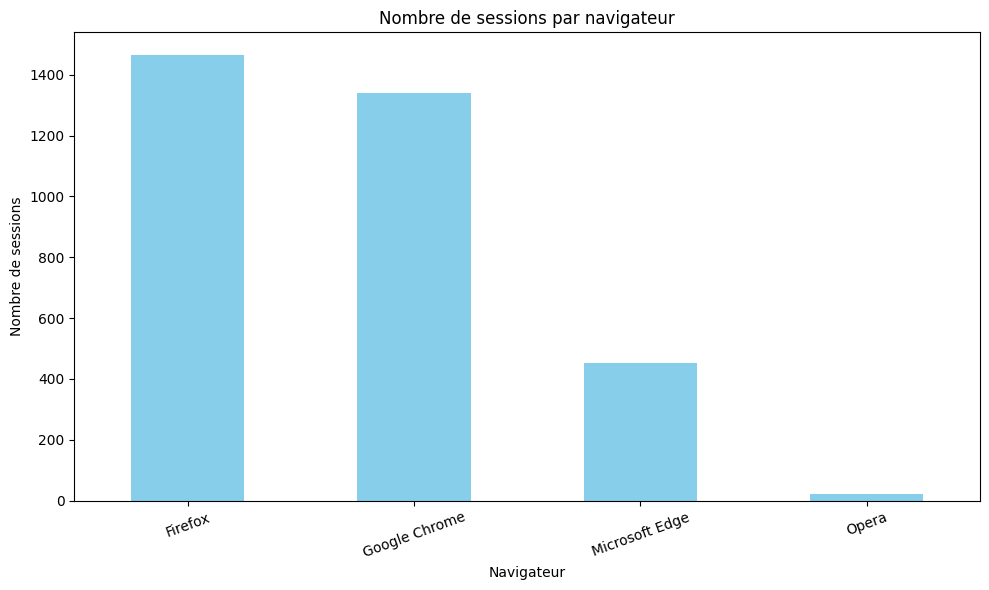

In [9]:
sessions_par_navigateur.plot(kind="bar", figsize=(10, 6), color="skyblue")

plt.title("Nombre de sessions par navigateur")
plt.xlabel("Navigateur")
plt.ylabel("Nombre de sessions")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

### Interprétation — Navigateurs

| Navigateur | Sessions | Part |
| --- | ---: | ---: |
| Firefox | 1 466 | 44,71 % |
| Google Chrome | 1 339 | 40,84 % |
| Microsoft Edge | 451 | 13,75 % |
| Opera | 23 | 0,70 % |

**Constat :** Firefox et Chrome concentrent 85,55 % des sessions. Opera est très peu représenté. Ces parts concernent les sessions, pas les utilisateurs.

## Exploration des utilisateurs

Chaque utilisateur constitue une classe à prédire. Nous examinons le nombre de sessions disponibles par utilisateur afin d’évaluer l’équilibre entre les classes.

Nombre d’utilisateurs : 247


count    247.000000
mean      13.275304
std        8.862380
min        4.000000
25%        7.000000
50%       12.000000
75%       16.000000
max       75.000000
Name: count, dtype: float64


Les 10 utilisateurs les plus représentés :


util
skm    75
slq    71
cjr    46
flj    42
hjs    37
vfo    35
shh    34
nqg    34
fwf    33
kwi    31
Name: count, dtype: int64


Les 10 utilisateurs les moins représentés :


util
azn    4
rff    4
jkt    4
fyg    4
jew    4
zll    4
itt    4
lra    4
bez    4
crn    4
Name: count, dtype: int64

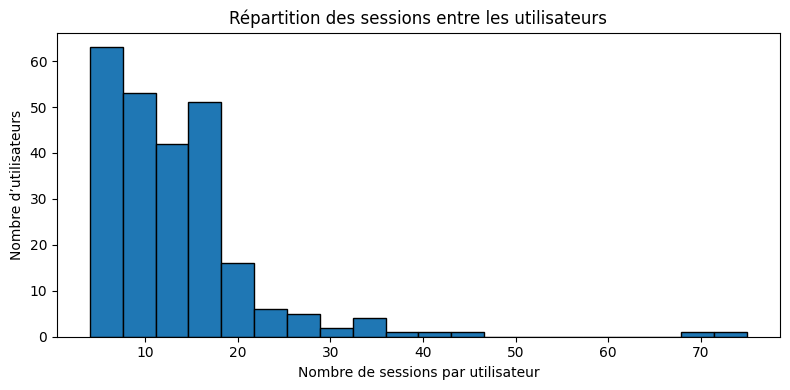

In [10]:
sessions_par_utilisateur = df_train["util"].value_counts()

print("Nombre d’utilisateurs :", len(sessions_par_utilisateur))

display(sessions_par_utilisateur.describe())

print("\nLes 10 utilisateurs les plus représentés :")
display(sessions_par_utilisateur.head(10))

print("\nLes 10 utilisateurs les moins représentés :")
display(sessions_par_utilisateur.tail(10))

plt.figure(figsize=(8, 4))
plt.hist(sessions_par_utilisateur, bins=20, edgecolor="black")
plt.title("Répartition des sessions entre les utilisateurs")
plt.xlabel("Nombre de sessions par utilisateur")
plt.ylabel("Nombre d’utilisateurs")
plt.tight_layout()
plt.show()

### Interprétation — Utilisateurs

| Indicateur | Résultat |
| --- | ---: |
| Utilisateurs distincts | 247 |
| Minimum de sessions par utilisateur | 4 |
| Médiane | 12 |
| Moyenne | 13,28 |
| Maximum | 75 |

**Conséquence :** les classes sont inégalement représentées. Les utilisateurs ayant peu de sessions fournissent moins d’exemples pour l’apprentissage ; il faudra examiner leurs performances en validation.

## Relation entre utilisateur et navigateur

Nous croisons l’identité des utilisateurs et les navigateurs utilisés, puis comptons le nombre de navigateurs distincts observés pour chaque utilisateur. Cette analyse permet d’étudier si le navigateur peut constituer un indice pour l’identification.

In [11]:
table_util_navigateur = pd.crosstab(
    df_train["util"],
    df_train["navigateur"],
)

display(table_util_navigateur.head(10))

nb_navigateurs_par_utilisateur = (
    table_util_navigateur.gt(0).sum(axis=1)
)

print("\nNombre de navigateurs différents par utilisateur :")

display(
    nb_navigateurs_par_utilisateur.value_counts().sort_index()
)

navigateur,Firefox,Google Chrome,Microsoft Edge,Opera
util,,,,
aho,0,10,0,0
ajo,13,0,0,0
akx,0,14,0,0
ald,0,15,0,0
ats,12,0,0,0
avt,15,0,0,0
azn,0,4,0,0
azo,0,10,0,0
azx,0,10,0,0



Nombre de navigateurs différents par utilisateur :


1    247
Name: count, dtype: int64

### Interprétation — Utilisateur et navigateur

| Observation dans le train | Interprétation |
| --- | --- |
| 247 utilisateurs sur 247 utilisent un seul navigateur | Le navigateur est stable dans les sessions observées. |
| Plusieurs utilisateurs partagent un navigateur | Cet indice peut réduire les identités possibles, mais ne suffit pas à identifier une personne. |
| Observation limitée au jeu d’entraînement | La stabilité du navigateur dans de nouvelles sessions reste à vérifier. |

## Séparation des actions et des marqueurs temporels

Les traces sont séparées en deux listes par session. La colonne `traces` conserve leur ordre initial.

In [12]:
def est_marqueur_temporel(trace):
    return re.match(r"^t\d+$", trace) is not None

def extraire_action(traces):
    actions = []
    
    for trace in traces:
        if not est_marqueur_temporel(trace):
            actions.append(trace)
            
    return actions

def extraire_temps(traces):
    temps = []
    
    for trace in traces:
        if est_marqueur_temporel(trace):
            temps.append(int(trace[1:])) 
    return temps


df_train["actions"] = df_train["traces"].apply(extraire_action)
df_train["temps"] = df_train["traces"].apply(extraire_temps)

display(df_train[["traces", "actions", "temps"]].head(20))

,traces,actions,temps
0,[Création d'un écran(infologic.core.accueil.Ac...,[Création d'un écran(infologic.core.accueil.Ac...,"[5, 10, 15, 20, 25, 30, 35, 40, 45, 50, 55, 60..."
1,[Création d'un écran(infologic.core.gui.contro...,[Création d'un écran(infologic.core.gui.contro...,"[5, 10, 15, 20, 25, 30, 35, 40, 45, 50, 55, 60..."
2,[Affichage d'une dialogue(infologic.core.gui.c...,[Affichage d'une dialogue(infologic.core.gui.c...,"[5, 10, 15, 20, 25, 30, 35, 40, 45, 50, 55, 60..."
3,[Création d'un écran(infologic.core.gui.contro...,[Création d'un écran(infologic.core.gui.contro...,"[5, 10, 15, 20, 25, 30, 35, 40, 45, 50, 55, 60..."
4,[Affichage d'une dialogue(infologic.acti.modul...,[Affichage d'une dialogue(infologic.acti.modul...,"[5, 10, 10, 15, 20, 25, 30, 30, 35, 40, 45, 50..."
5,[Création d'un écran(infologic.crm.modules.CRM...,[Création d'un écran(infologic.crm.modules.CRM...,"[5, 10, 15, 20, 25, 30, 35, 40, 45, 50, 55, 60..."
6,"[Exécution d'un bouton, t5, Exécution d'un bou...","[Exécution d'un bouton, Exécution d'un bouton(...","[5, 10, 15, 20, 25, 30, 35, 40, 45, 50, 55, 60..."
7,"[Exécution d'un bouton, Exécution d'un bouton,...","[Exécution d'un bouton, Exécution d'un bouton,...","[5, 10, 15, 20, 25, 30, 35, 40, 45, 50, 55, 60..."
8,[Création d'un écran(infologic.core.accueil.Ac...,[Création d'un écran(infologic.core.accueil.Ac...,"[5, 10, 15, 20, 25, 25, 30, 35, 40, 45, 50, 55..."
9,[Création d'un écran(infologic.core.accueil.Ac...,[Création d'un écran(infologic.core.accueil.Ac...,"[5, 10, 15, 20, 25, 30, 35, 40, 45, 50, 55, 60..."


## Calcul des caractéristiques simples

| Caractéristique | Définition |
| --- | --- |
| `nb_traces` | Nombre total d’éléments de la séquence |
| `nb_actions` | Nombre d’actions sans les marqueurs temporels |
| `nb_marqueurs_temporels` | Nombre de marqueurs enregistrés, répétitions incluses |
| `dernier_repere_s` | Plus grand repère temporel, en secondes ; durée exacte non garantie |

In [13]:
def dernier_repere(temps):
    if temps:
        return max(temps)

    return float("nan")


df_train["nb_traces"] = df_train["traces"].apply(len)
df_train["nb_actions"] = df_train["actions"].apply(len)
df_train["nb_marqueurs_temporels"] = df_train["temps"].apply(len)

df_train["dernier_repere_s"] = df_train["temps"].apply(
    dernier_repere
)

colonnes_resume = [
    "session_id",
    "util",
    "navigateur",
    "nb_traces",
    "nb_actions",
    "nb_marqueurs_temporels",
    "dernier_repere_s",
]

display(df_train[colonnes_resume].head(10))

,session_id,util,navigateur,nb_traces,nb_actions,nb_marqueurs_temporels,dernier_repere_s
0,1,nuh,Firefox,3128,2514,614,2905
1,2,muz,Google Chrome,136,90,46,230
2,3,zrx,Microsoft Edge,766,608,158,750
3,4,pou,Firefox,1199,886,313,1445
4,5,ald,Google Chrome,233,173,60,275
5,6,shh,Firefox,329,288,41,205
6,7,fwf,Firefox,105,65,40,200
7,8,slq,Google Chrome,89,73,16,80
8,9,cje,Google Chrome,160,124,36,175
9,10,byo,Firefox,2444,1925,519,2595


## Longueur des sessions et cas particuliers

,nb_actions,nb_marqueurs_temporels,dernier_repere_s
count,3279.000000,3279.000000,3279.000000
mean,692.359561,157.879231,751.530955
std,1005.873878,212.513833,1006.277841
min,0.000000,1.000000,5.000000
25%,153.000000,38.000000,185.000000
50%,340.000000,82.000000,395.000000
75%,818.500000,197.500000,945.000000
max,11977.000000,2491.000000,11790.000000


Sessions sans actions : 1


,session_id,util,navigateur,traces
1251,1252,fvc,Google Chrome,"[t5, t10, t15]"



Les 5 sessions contenant le plus d’actions :


,session_id,util,navigateur,nb_traces,nb_actions,nb_marqueurs_temporels,dernier_repere_s
3082,3083,wvy,Firefox,14468,11977,2491,11790
3234,3235,fxg,Firefox,13443,11505,1938,9080
84,85,urs,Google Chrome,12274,10625,1649,8245
2812,2813,wvy,Firefox,11956,9707,2249,10625
2520,2521,fjb,Microsoft Edge,11275,9430,1845,8645


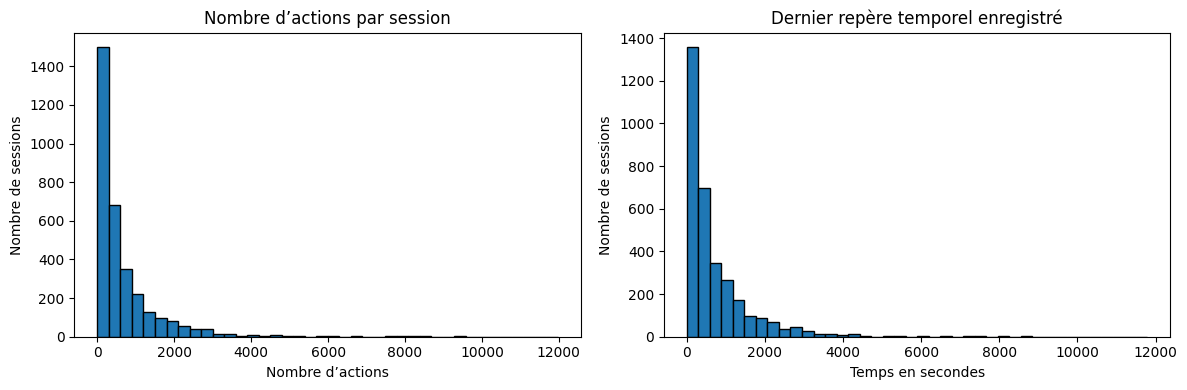

In [14]:
display(
    df_train[
        ["nb_actions", "nb_marqueurs_temporels", "dernier_repere_s"]
    ].describe()
)

sessions_sans_actions = df_train.loc[
    df_train["nb_actions"].eq(0),
    ["session_id", "util", "navigateur", "traces"],
]

print("Sessions sans actions :", len(sessions_sans_actions))
display(sessions_sans_actions)

print("\nLes 5 sessions contenant le plus d’actions :")
display(df_train.nlargest(5, "nb_actions")[colonnes_resume])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(df_train["nb_actions"], bins=40, edgecolor="black")
axes[0].set_title("Nombre d’actions par session")
axes[0].set_xlabel("Nombre d’actions")
axes[0].set_ylabel("Nombre de sessions")

axes[1].hist(
    df_train["dernier_repere_s"].dropna(),
    bins=40,
    edgecolor="black",
)
axes[1].set_title("Dernier repère temporel enregistré")
axes[1].set_xlabel("Temps en secondes")
axes[1].set_ylabel("Nombre de sessions")

plt.tight_layout()
plt.show()

### Interprétation — Longueur des sessions

| Indicateur | Résultat | Lecture |
| --- | ---: | --- |
| Médiane du nombre d’actions | 340 | Repère central de la distribution |
| Moyenne du nombre d’actions | 692,36 | Supérieure à la médiane : influence des sessions longues |
| Maximum du nombre d’actions | 11 977 | Forte variation de longueur |
| Médiane du dernier repère | 395 s | Repère temporel, pas durée exacte |
| Sessions sans action | 1 | Session 1252, utilisateur `fvc` : uniquement `t5`, `t10`, `t15` |

**Décision :** conserver les sessions atypiques à ce stade et examiner leur effet lors de la validation.

## Exploration des types d’actions

Le nom de chaque action est séparé de son contexte et de son suffixe de modification. Les fréquences comptent les occurrences sur l’ensemble des sessions.

Nombre de types d’actions : 35


actions
Exécution d'un bouton                            510645
Saisie dans un champ                             265633
Sélection d'un écran                             206813
Fermeture d'une dialogue                         171026
Affichage d'une dialogue                         168928
Lancement d'une action générique                 115283
Sélection d’un onglet                            109209
Raccourci                                         82176
Création d'un écran                               76930
Chainage                                          68194
Double-clic                                       67992
Retour sur un écran                               61946
Affichage d'un toast                              52091
Clic sur une grille d'historique de recherche     50273
Entrée en saisie dans un formulaire               39276
Filtrage / Tri                                    37628
Sélection d'un flag                               32252
Lancement d'une stat                    

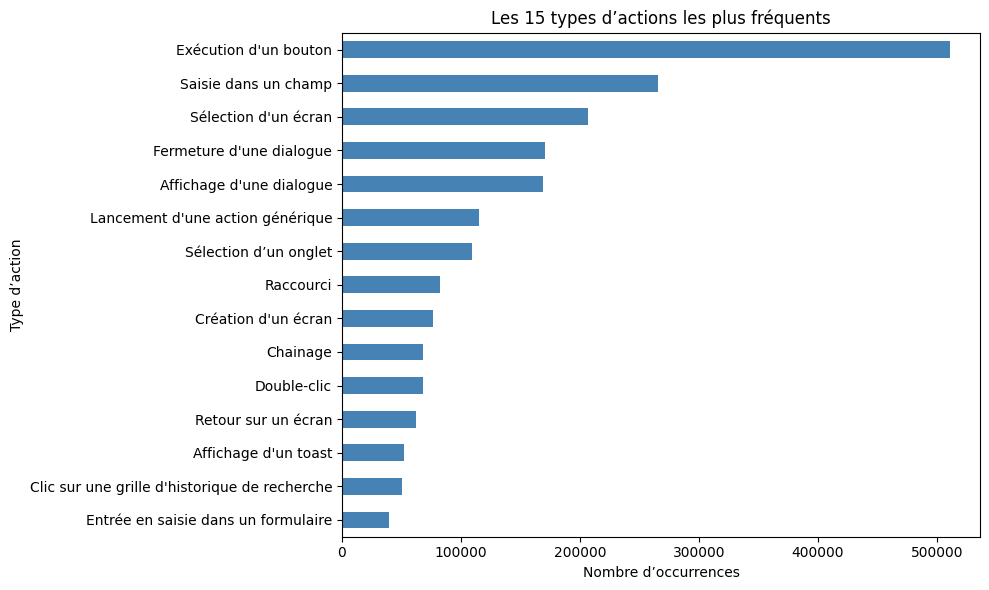

In [15]:
def extraire_type_action(action):
    nom = re.split(r"[(<$]", action, maxsplit=1)[0].strip()

    if nom.endswith("1"):
        nom = nom[:-1].rstrip()

    return nom


toutes_les_actions = df_train["actions"].explode().dropna()
types_actions = toutes_les_actions.map(extraire_type_action)
frequences_actions = types_actions.value_counts()

print("Nombre de types d’actions :", types_actions.nunique())
display(frequences_actions.head(20))

frequences_actions.head(15).sort_values().plot(
    kind="barh",
    figsize=(10, 6),
    color="steelblue",
)

plt.title("Les 15 types d’actions les plus fréquents")
plt.xlabel("Nombre d’occurrences")
plt.ylabel("Type d’action")
plt.tight_layout()
plt.show()

### Interprétation — Types d’actions

| Observation | Résultat |
| --- | --- |
| Types d’actions distincts après extraction | 35 |
| Action la plus fréquente | Exécution d’un bouton : 510 645 occurrences |
| Deuxième action | Saisie dans un champ : 265 633 occurrences |

**Limite :** les fréquences globales sont influencées par les sessions longues ; elles ne démontrent pas encore qu’une action distingue un utilisateur.

## Exploration des contextes, configurations et chaînes

| Délimiteurs | Information extraite |
| --- | --- |
| `(…)` | Écran ou contexte |
| `<…>` | Configuration d’écran |
| `$…$` | Chaîne de fiche |

Seules les informations explicitement présentes dans les traces sont extraites.

In [16]:
pattern_ecran = re.compile(r"\((.*?)\)")
pattern_configuration = re.compile(r"<(.*?)>")
pattern_chaine = re.compile(r"\$(.*?)\$")


def extraire_contextes(actions, pattern):
    valeurs = []

    for action in actions:
        valeurs.extend(pattern.findall(action))

    return valeurs


df_train["ecrans_contextes"] = df_train["actions"].apply(
    lambda actions: extraire_contextes(actions, pattern_ecran)
)

df_train["configurations"] = df_train["actions"].apply(
    lambda actions: extraire_contextes(actions, pattern_configuration)
)

df_train["chaines"] = df_train["actions"].apply(
    lambda actions: extraire_contextes(actions, pattern_chaine)
)

for colonne in ["ecrans_contextes", "configurations", "chaines"]:
    valeurs = df_train[colonne].explode().dropna()

    print(f"\n{colonne} : {valeurs.nunique()} valeurs distinctes")
    display(valeurs.value_counts().head(10))


ecrans_contextes : 418 valeurs distinctes


ecrans_contextes
MAINT                                                               37932
infologic.core.gui.controllers.BlankController                      33615
infologic.core.FichiersController                                   18425
infologic.crm.modules.CRM_PLANNING.planning.PlanningController      17564
DEV                                                                 15759
infologic.infoc.statmodif.fichierbase.StatFBController              15006
infologic.core.gui.controllers.nested.InputFormNestedWindow          9936
infologic.orga.modules.OR_FICHIERTRAVAIL.InstanceForm                9907
infologic.core.accueil.AccueilController                             8484
infologic.core.gui.controllers.nested.homeview.InputFormHomeView     8438
Name: count, dtype: int64


configurations : 219 valeurs distinctes


configurations
DEF_03/24        18186
DEF_07/23        16313
STD              10544
INSTALLATEUR      9567
TELEM_MINIMAL     7595
001               4116
MT_AppelN1        3092
ACCUEIL_INST      2648
005               2630
dispatch          2279
Name: count, dtype: int64


chaines : 76 valeurs distinctes


chaines
VT       53480
GP       39424
EDI      33359
TEC      26315
OT       24509
SV       23681
GESCO    22173
JCP      21653
ST       17160
WEB      11410
Name: count, dtype: int64

### Interprétation — Contextes

| Information | Valeurs distinctes | Valeur la plus fréquente |
| --- | ---: | --- |
| Écrans ou contextes | 418 | `MAINT` |
| Configurations | 219 | `DEF_03/24` |
| Chaînes | 76 | `VT` |

**Hypothèse :** les contextes de travail peuvent aider à distinguer les utilisateurs. Leur utilité devra être mesurée en validation.

## Actions réalisées en modification

| Caractéristique | Définition |
| --- | --- |
| `nb_actions_modification` | Nombre d’actions terminées par le suffixe `1` |
| `part_actions_modification` | Nombre d’actions en modification divisé par le nombre total d’actions |

La proportion est comprise entre 0 et 1. Elle reste manquante pour la session sans action, car le ratio n’est pas défini.

In [17]:
def compter_modifications(actions):
    return sum(action.endswith("1") for action in actions)


df_train["nb_actions_modification"] = df_train["actions"].apply(
    compter_modifications
)

denominateur = df_train["nb_actions"].replace(0, float("nan"))

df_train["part_actions_modification"] = (
    df_train["nb_actions_modification"] / denominateur
)

display(
    df_train[
        ["session_id", "util", "nb_actions", "nb_actions_modification",
         "part_actions_modification"]
    ].head(10)
)

display(
    df_train[
        ["nb_actions_modification", "part_actions_modification"]
    ].describe()
)

,session_id,util,nb_actions,nb_actions_modification,part_actions_modification
0,1,nuh,2514,4,0.001591
1,2,muz,90,26,0.288889
2,3,zrx,608,50,0.082237
3,4,pou,886,64,0.072235
4,5,ald,173,2,0.011561
5,6,shh,288,0,0.000000
6,7,fwf,65,0,0.000000
7,8,slq,73,0,0.000000
8,9,cje,124,0,0.000000
9,10,byo,1925,1047,0.543896


,nb_actions_modification,part_actions_modification
count,3279.000000,3278.000000
mean,108.298872,0.155358
std,234.307448,0.187719
min,0.000000,0.000000
25%,4.000000,0.010817
50%,34.000000,0.090909
75%,112.000000,0.224215
max,4448.000000,0.907975


## Vérification de la conservation des données brutes

`df_raw` doit garder ses quatre colonnes initiales. Les colonnes calculées appartiennent uniquement à `df_train`. Les deux vérifications suivantes doivent renvoyer `True`.

In [18]:
print("Colonnes des données brutes :")
print(df_raw.columns.tolist())

print("\nColonnes de la copie de travail :")
print(df_train.columns.tolist())

print("\nMême nombre de sessions :", len(df_raw) == len(df_train))
print(
    "Données brutes préservées dans la copie :",
    df_raw.equals(df_train[df_raw.columns]),
)

Colonnes des données brutes :
['session_id', 'util', 'navigateur', 'traces']

Colonnes de la copie de travail :
['session_id', 'util', 'navigateur', 'traces', 'actions', 'temps', 'nb_traces', 'nb_actions', 'nb_marqueurs_temporels', 'dernier_repere_s', 'ecrans_contextes', 'configurations', 'chaines', 'nb_actions_modification', 'part_actions_modification']

Même nombre de sessions : True
Données brutes préservées dans la copie : True


## Bilan de la première exploration

| Partie | Résultat |
| --- | --- |
| Données | 3 279 sessions, 247 utilisateurs |
| Qualité de structure | Aucun champ vide ni session strictement dupliquée détecté |
| Répartition des classes | 4 à 75 sessions par utilisateur |
| Navigateurs | Un navigateur observé par utilisateur dans le train |
| Actions | 35 types ; longueurs très variables |
| Contextes | 418 écrans ou contextes, 219 configurations, 76 chaînes |
| Cas particulier | Une session sans action, conservée |
| Modification | Médiane : 34 actions par session ; proportion médiane : 9,09 %, moyenne par session : 15,54 % ; une proportion non définie pour la session sans action |
